# seekdb × hipVS — AMD GPU 批量向量检索

基于用户提供的 AMD 课程 Notebook 整理。按索引选择 `lib=vsag` 或 `lib=cuvs`，比较单条查询和批量算子，展示真实吞吐、Recall@10 和记分牌。

**七步流程**：①环境与硬件自检 ②工作原理 ③启动与准备数据 ④单查 CPU/GPU ⑤批量提速 ⑥召回与正确性 ⑦总结记分牌。

依赖课程 `seekdb-hipvs` 镜像内的批量查询后端，不需要模型 API Key。硬件型号、耗时和召回以本次运行输出为准；gfx1100 不能单独证明商业型号为 W7900。


**运行方式：先选择 Restart Kernel and Run All Cells。先完成第 3 节启动和数据准备，再执行查询。保存的输出不代表重启后的内核中仍有变量；缺少前置结果时，单元会提示应先运行哪一节。**


原目录单文件修复版：保持本文件名和课程 lib 目录，先执行初始化，再从头运行全部单元。不要把原课程保存的旧输出当成本次成绩。


In [1]:
from pathlib import Path
import os
import time
import uuid


def _notebook_directory():
    candidates = []
    for variable_name in ("__vsc_ipynb_file__", "__session__"):
        notebook_path = globals().get(variable_name)
        if notebook_path:
            candidates.append(Path(notebook_path).expanduser().resolve().parent)
    candidates.append(Path.cwd().resolve())

    for candidate in dict.fromkeys(candidates):
        if (candidate / "lib" / "seekdb_demo.py").is_file():
            return candidate
    return Path.cwd().resolve()


def _load_or_create_scope_uuid(file_path, timeout=5):
    deadline = time.monotonic() + timeout
    last_error = None

    while time.monotonic() < deadline:
        try:
            return str(uuid.UUID(file_path.read_text(encoding="ascii").strip()))
        except FileNotFoundError:
            generated_id = str(uuid.uuid4())
            try:
                descriptor = os.open(
                    file_path,
                    os.O_WRONLY | os.O_CREAT | os.O_EXCL,
                    0o600,
                )
            except FileExistsError:
                pass
            else:
                try:
                    with os.fdopen(descriptor, "w", encoding="ascii") as stream:
                        stream.write(generated_id + "\n")
                        stream.flush()
                        os.fsync(stream.fileno())
                except Exception:
                    file_path.unlink(missing_ok=True)
                    raise
                return generated_id
        except (OSError, ValueError) as exc:
            last_error = exc
        time.sleep(0.05)

    raise RuntimeError(
        f"Unable to read a valid telemetry UUID from {file_path}: {last_error}"
    )


_TELEMETRY_ID_FILE = _notebook_directory() / ".seekdb_telemetry_instance_id"
_TELEMETRY_INSTANCE_ID = _load_or_create_scope_uuid(_TELEMETRY_ID_FILE)
os.environ["SEEKDB_TELEMETRY_INSTANCE_ID"] = _TELEMETRY_INSTANCE_ID

In [2]:
from pathlib import Path
import json
import sys, os, subprocess, time, importlib

# ---- locate the sibling lib/ folder robustly (VS Code / JupyterLab / nbconvert) ----
def _find_lib():
    cands = []
    p = globals().get("__vsc_ipynb_file__")      # VS Code injects the .ipynb abs path
    if p: cands.append(os.path.dirname(os.path.abspath(p)))
    p = globals().get("__session__")             # some Jupyter builds expose the .ipynb path
    if p: cands.append(os.path.dirname(os.path.abspath(p)))
    cands.append(os.getcwd())                    # interactive Jupyter / nbconvert cwd = notebook dir
    for d in dict.fromkeys(cands):               # de-dup, keep order
        if d and os.path.isfile(os.path.join(d, "lib", "seekdb_demo.py")):
            return os.path.join(d, "lib")
    return os.path.join(os.getcwd(), "lib")      # last resort
_LIB = _find_lib(); sys.path.insert(0, _LIB)
import seekdb_demo as sk; importlib.reload(sk)
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

# ---- AMD showcase plot theme ----
AMD_RED, CPU_GRAY = "#ED1C24", "#5B6770"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "#cccccc",
    "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
print("imports + theme ready.  lib =", _LIB)

# Original-directory repair. These definitions run in the existing helper module.
# All repair code is kept in this Notebook; the original lib file is unchanged.
_COURSE_RUNTIME_FIXES = r'''
def sh(cmd, inp=None):
    result = subprocess.run(cmd, input=inp, capture_output=True, text=True, timeout=660)
    if cmd and cmd[0] == "mysql" and result.returncode:
        raise RuntimeError("Notebook SQL failed: " + result.stderr[:1000])
    return result

def sql(q, timed=False):
    t = time.perf_counter()
    r = sh(MYSQL + ["-e", "SET ob_query_timeout=600000000;" + q])
    dt = time.perf_counter() - t
    return (dt, r.returncode) if timed else (r.returncode, r.stdout, r.stderr)

def require_notebook_state(namespace, names, instruction):
    """Report an interrupted/out-of-order notebook before using stale outputs."""
    missing = [name for name in names if name not in namespace]
    if missing:
        raise RuntimeError("Notebook prerequisites missing: %s. %s" % (", ".join(missing), instruction))

def _probe_vector(probe_id=1):
    rows = sql_rows("use vec; select pv from probes_100 where id=%d" % probe_id)
    if not rows or not rows[0] or rows[0][0] in (None, "NULL", ""):
        raise RuntimeError("Probe %d is missing from probes_100. Run section 3 data preparation successfully before querying." % probe_id)
    return rows[0][0]

def wait_index_ready(table="t_cuvs", k=10, timeout=90, floor=15):
    """Wait for the async vector-index build: a short floor, then poll a probe
    query until its top-k stabilises (more robust than a fixed sleep)."""
    vec = _probe_vector()
    time.sleep(floor)
    t0 = time.time(); last = None
    while vec and time.time() - t0 < timeout:
        rows = sql_rows("use vec; select c1 from %s order by l2_distance(c2,%s) "
                        "approximate limit %d" % (table, vec, k))
        if len(rows) >= k:
            cur = tuple(r[0] for r in rows[:k])
            if cur == last:
                return round(time.time() - t0 + floor)
            last = cur
        time.sleep(3)
    raise TimeoutError("Vector index %s did not return stable top-%d results within %ss; data preparation is incomplete." % (table, k, timeout))

def cpu_lateral(N, k=10):
    """CPU baseline: nested-loop similarity join on the lib=vsag (CPU/VSAG) index."""
    q = ("use vec; truncate cpu_out; insert into cpu_out "
         "select p.id, n.c1 from probes_%d p, lateral("
         "select c1 from t_vsag order by l2_distance(c2,p.pv) approximate limit %d) n;" % (N, k))
    elapsed = sql(q, timed=True)[0]
    output_table = "cpu_out" if "truncate cpu_out" in q else "bk_out"
    output_count = int(sql_rows("use vec; select count(*) from " + output_table)[0][0])
    if output_count != N * k:
        raise RuntimeError("Incomplete batch result: %s %d != %d" % (output_table, output_count, N * k))
    return elapsed

def gpu_batch(N, k=10):
    """GPU batch operator: one dbms_vector.batch_knn call for all N probes."""
    q = 'use vec; call dbms_vector.batch_knn("t_cuvs","probes_%d",%d,"bk_out");' % (N, k)
    elapsed = sql(q, timed=True)[0]
    output_table = "cpu_out" if "truncate cpu_out" in q else "bk_out"
    output_count = int(sql_rows("use vec; select count(*) from " + output_table)[0][0])
    if output_count != N * k:
        raise RuntimeError("Incomplete batch result: %s %d != %d" % (output_table, output_count, N * k))
    return elapsed

def single_query(table, probe_id=1, k=10):
    """Time one APPROXIMATE query (probe vector taken from probes_100)."""
    v = _probe_vector(probe_id)
    q = "use vec; select c1 from %s order by l2_distance(c2,%s) approximate limit %d;" % (table, v, k)
    return sql(q, timed=True)[0]

def start_observer(base="/workspace/run/obs1"):
    # The course shell script may remove an existing base directory; do not use it.
    from pathlib import Path
    import socket
    binary = (Path(SEEKDB) / "bin/seekdb").resolve()
    base = Path(base).expanduser().resolve()
    if not binary.is_file():
        raise RuntimeError("Course binary is missing: " + str(binary))
    if base == Path("/") or base == Path.home().resolve():
        raise RuntimeError("Unsafe database directory")
    def matching_pid():
        for entry in Path("/proc").iterdir():
            if not entry.name.isdigit():
                continue
            try:
                args = (entry / "cmdline").read_bytes().split(b"\0")
                if (entry / "exe").resolve() == binary and ("--base-dir=" + str(base)).encode() in args:
                    return int(entry.name)
            except OSError:
                continue
        return None
    owned_pid = matching_pid()
    try:
        with socket.create_connection(("127.0.0.1", 2881), timeout=2):
            occupied = True
    except OSError:
        occupied = False
    if occupied and not owned_pid:
        raise RuntimeError("Port 2881 belongs to another server. Do not stop unrelated instances.")
    process = None
    if not owned_pid:
        base.mkdir(parents=True, exist_ok=True)
        env = dict(os.environ)
        env["LD_LIBRARY_PATH"] = ":".join([str(binary.parent.parent / "bridge"), "/opt/hipvs/lib", "/opt/rocm/lib", env.get("LD_LIBRARY_PATH", "")])
        command = [str(binary), "--base-dir=" + str(base), "--port=2881", "--nodaemon",
                   "--parameter", "_memory_budget=16G", "--parameter", "datafile_size=20G",
                   "--parameter", "datafile_maxsize=40G", "--parameter", "log_disk_size=10G"]
        with (base / "notebook-launch.log").open("ab") as console:
            process = subprocess.Popen(command, cwd=base, env=env, stdout=console, stderr=subprocess.STDOUT, start_new_session=True)
        owned_pid = process.pid
    deadline = time.monotonic() + 180
    while time.monotonic() < deadline:
        if process is not None and process.poll() is not None:
            raise RuntimeError("seekdb exited during startup; inspect " + str(base / "notebook-launch.log"))
        ready = subprocess.run(MYSQL + ["-N", "-e", "select 1"], capture_output=True, text=True, timeout=5)
        if ready.returncode == 0:
            print("observer ready on 2881; base=" + str(base) + "; pid=" + str(owned_pid))
            return True
        time.sleep(1)
    raise TimeoutError("seekdb was not ready within 180s; inspect " + str(base / "notebook-launch.log"))

'''
exec(compile(_COURSE_RUNTIME_FIXES, "course_notebook_runtime_fixes", "exec"), sk.__dict__)
print("original-directory runtime fixes loaded:", Path(sk.__file__).resolve())


imports + theme ready.  lib = /workspace/seekdb_hipvs_notebook/lib
original-directory runtime fixes loaded: /workspace/seekdb_hipvs_notebook/lib/seekdb_demo.py


## 1. 环境与硬件自检

确认我们真的运行在 **AMD GPU + ROCm** 上,且发行的 seekdb 二进制已**编译链接** hipVS/cuVS GPU 后端。


In [3]:
gi = sk.gpu_info(); si = sk.stack_info()
def _row(k, v): return {"项 / item": k, "值 / value": v}
env = pd.DataFrame([
    _row("GPU",               gi["name"]),
    _row("架构 arch",         "%s / RDNA3" % gi["gfx"]),
    _row("显存 VRAM",         ("%d MB total, %s MB used" % (gi["vram_total_mb"], gi["vram_used_mb"])) if gi["vram_total_mb"] else "n/a"),
    _row("ROCm",              gi["rocm"] or "n/a"),
    _row("seekdb 二进制 bin", "OK" if si["seekdb_bin"] else "MISSING"),
    _row("cuVS 桥接库 bridge","OK" if si["bridge"] else "MISSING"),
    _row("libcuvs 链接 link", "%d   (>0 = GPU backend compiled in)" % si["libcuvs_linked"]),
    _row("SEEKDB_HOME",       sk.SEEKDB),
])
env

,项 / item,值 / value
0,GPU,AMD Radeon Graphics
1,架构 arch,gfx1100 / RDNA3
2,显存 VRAM,"49136 MB total, 26 MB used"
3,ROCm,7.2.4
4,seekdb 二进制 bin,OK
5,cuVS 桥接库 bridge,OK
6,libcuvs 链接 link,3 (>0 = GPU backend compiled in)
7,SEEKDB_HOME,/seekdb_workspace


## 2. 工作原理

seekdb 的向量抽象层(obvsag C-API)**按索引**选择后端:`lib=vsag` 走 CPU(VSAG / HNSW),`lib=cuvs` 走 AMD GPU。GPU 路径经一层**纯 C 桥接**调用 hipVS 的 **CAGRA** 图索引;任何不支持的场景(带过滤 / 删除后 / 非 L2)**安全回退 CPU**,绝不给错结果。

```text
 SQL:  CREATE ... WITH (lib=cuvs)   |   CALL dbms_vector.batch_knn(...)
                 │
                 ▼
        obvsag 向量抽象层  ──► lib=vsag ─────────────► VSAG (CPU HNSW)
                 │
                 └──► lib=cuvs ──► libseekdb_cuvs_bridge.so ──► hipVS libcuvs (CAGRA) ──► ROCm / gfx1100
```

**两种用法**
- **声明式**:`... VECTOR INDEX idx(c2) WITH (distance=l2, type=hnsw, lib=cuvs)` —— 该索引走 GPU,同库其它索引仍走 CPU。
- **批量算子**:`CALL dbms_vector.batch_knn('t_cuvs', 'probes', 10, 'bk_out')` —— N 条探针**一次**喂给 GPU(GPU 真正发力点)。


## 3. 启动 seekdb + 准备数据

启动 observer(首次自动 bootstrap;GPU 完全由 `lib=cuvs` 驱动,**无环境变量**),然后建两张**同源** 10k 向量表 —— `t_cuvs`(GPU)与 `t_vsag`(CPU),并生成不同批量大小的探针表。


In [4]:
from pathlib import Path
import time
if "sk" not in globals():
    raise RuntimeError("Run the initialization/import cell first, or use Restart Kernel and Run All Cells.")
for _name in ("_DATA_READY", "df", "cpu", "gpu", "r_cpu", "r_gpu", "score"):
    globals().pop(_name, None)
import json

_OBSERVER_BASE = Path("/workspace/run/obs1")
if not sk.start_observer(str(_OBSERVER_BASE)):
    raise RuntimeError("seekdb observer failed to start")
print("seekdb version:", sk.version())

_telemetry_file = _OBSERVER_BASE / "run" / "telemetry.json"
_deadline = time.monotonic() + 15
_last_error = None

while time.monotonic() < _deadline:
    try:
        _telemetry_text = _telemetry_file.read_text(encoding="utf-8")
        telemetry = json.loads(_telemetry_text)
        break
    except (FileNotFoundError, json.JSONDecodeError, OSError) as exc:
        _last_error = exc
        time.sleep(0.25)
else:
    _log_file = _OBSERVER_BASE / "log" / "seekdb.log"
    _diagnostics = []
    if _log_file.is_file():
        _diagnostics = [
            line
            for line in _log_file.read_text(errors="replace").splitlines()
            if "telemetry" in line.lower()
        ][-20:]
    raise RuntimeError(
        f"telemetry.json was not generated within 15s: {_telemetry_file}\n"
        f"Last error: {_last_error}\n"
        f"Telemetry diagnostics:\n" + "\n".join(_diagnostics)
    )

print()
print(f"Complete telemetry.json: {_telemetry_file}")
print("telemetry.json parsed successfully; full runtime identifiers remain in the local file.")

observer ready on 2881; base=/workspace/run/obs1; pid=375
seekdb version: 5.7.25-OceanBase seekdb-v1.4.0.0

Complete telemetry.json: /workspace/run/obs1/run/telemetry.json
telemetry.json parsed successfully; full runtime identifiers remain in the local file.


In [5]:
if "sk" not in globals():
    raise RuntimeError("Run the initialization/import cell first, or use Restart Kernel and Run All Cells.")
for _name in ("_DATA_READY", "df", "cpu", "gpu", "r_cpu", "r_gpu", "score"):
    globals().pop(_name, None)
N_INDEX     = 10000
PROBE_SIZES = (100, 500, 1000, 2000, 4000)
ok, err = sk.setup_data(N_INDEX, PROBE_SIZES)
assert ok, "data load failed: %s" % err[:300]
print("data loaded: t_cuvs (lib=cuvs, GPU) + t_vsag (lib=vsag, CPU), %d vectors each" % N_INDEX)
waited = sk.wait_index_ready("t_cuvs", timeout=90)
print("vector index ready (~%ds)  |  t_cuvs = %s rows,  t_vsag = %s rows" % (
    waited,
    sk.sql_rows("use vec; select count(*) from t_cuvs")[0][0],
    sk.sql_rows("use vec; select count(*) from t_vsag")[0][0]))
_DATA_READY = True


data loaded: t_cuvs (lib=cuvs, GPU) + t_vsag (lib=vsag, CPU), 10000 vectors each


vector index ready (~20s)  |  t_cuvs = 10000 rows,  t_vsag = 10000 rows


## 4. 单条查询:CPU vs GPU(为何单查无收益)

一条 `... ORDER BY l2_distance(...) APPROXIMATE LIMIT 10`:`t_vsag` 走 CPU HNSW,`t_cuvs` 走 GPU cuVS。CPU 的 HNSW 已是亚毫秒,GPU 每次调用的固定开销(建图 / 传输 / kernel 启动)把优势吃掉 —— **单查约等于,甚至更慢**。


single query   CPU (lib=vsag): 7.75 ms    GPU (lib=cuvs): 13.22 ms


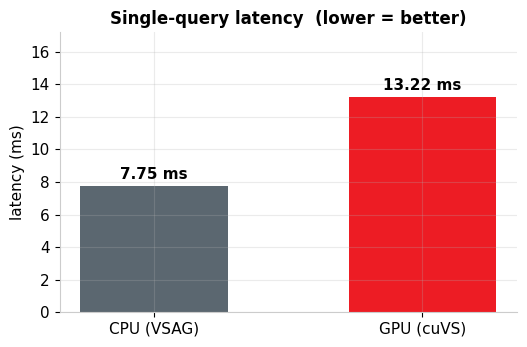

=> 单查 GPU 无收益。真正的加速在 *批量* -> 下一节。


In [6]:
if "sk" not in globals():
    raise RuntimeError("Run the initialization/import cell first, or use Restart Kernel and Run All Cells.")
sk.require_notebook_state(globals(), ['_DATA_READY'], 'Run section 3 startup AND data preparation first.')
globals().pop('cpu', None)
globals().pop('gpu', None)
globals().pop('score', None)
for _ in range(2):
    sk.single_query("t_cuvs"); sk.single_query("t_vsag")           # warm up
cpu = min(sk.single_query("t_vsag") for _ in range(5)) * 1000
gpu = min(sk.single_query("t_cuvs") for _ in range(5)) * 1000
print("single query   CPU (lib=vsag): %.2f ms    GPU (lib=cuvs): %.2f ms" % (cpu, gpu))

fig, ax = plt.subplots(figsize=(5.4, 3.6))
bars = ax.bar(["CPU (VSAG)", "GPU (cuVS)"], [cpu, gpu], color=[CPU_GRAY, AMD_RED], width=0.55)
ax.bar_label(bars, fmt="%.2f ms", padding=3, fontweight="bold")
ax.set_ylabel("latency (ms)"); ax.set_title("Single-query latency  (lower = better)")
ax.set_ylim(0, max(cpu, gpu) * 1.3)
plt.tight_layout(); plt.show()
print("=> 单查 GPU 无收益。真正的加速在 *批量* -> 下一节。")

## 5. 批量提速(核心):CPU 逐条 vs GPU 一次批量

同一批 N 条相似度查询:
- **CPU**:`probes JOIN t_vsag`(nested-loop,一条一次 knn,VSAG)—— 墙钟随 N **线性**增长。
- **GPU**:`dbms_vector.batch_knn(t_cuvs, probes, 10, bk_out)` —— **一次** GPU 调用处理全部 N 条,固定开销被摊薄。


In [7]:
if "sk" not in globals():
    raise RuntimeError("Run the initialization/import cell first, or use Restart Kernel and Run All Cells.")
sk.require_notebook_state(globals(), ['_DATA_READY', 'PROBE_SIZES'], 'Run section 3 data preparation first.')
globals().pop('df', None)
globals().pop('score', None)
df = sk.sweep(PROBE_SIZES)
df

,N,cpu_ms,gpu_ms,speedup,cpu_probes_s,gpu_probes_s
0,100,318.7,1170.2,0.27,314,85
1,500,1488.9,975.0,1.53,336,513
2,1000,2947.6,983.3,3.00,339,1017
3,2000,5882.8,1120.2,5.25,340,1785
4,4000,11802.0,1265.0,9.33,339,3162


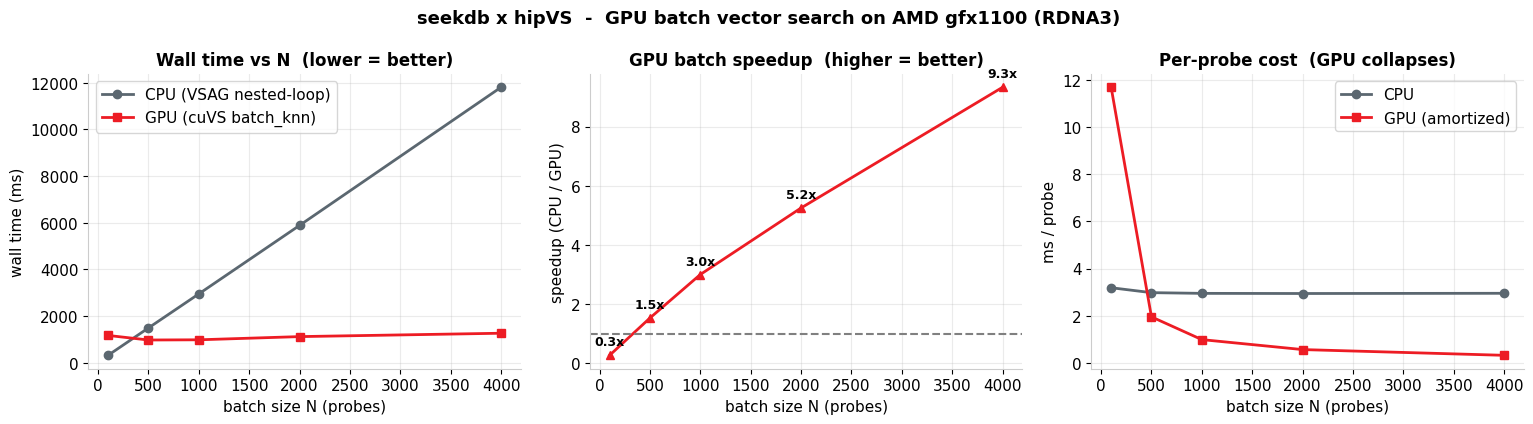

peak speedup: 9.3x at N=4000   ->  saved results/seekdb_hipvs_speedup.png + summary.csv


In [8]:
if "sk" not in globals():
    raise RuntimeError("Run the initialization/import cell first, or use Restart Kernel and Run All Cells.")
sk.require_notebook_state(globals(), ['df'], 'Run section 5: df = sk.sweep(PROBE_SIZES). A saved output is not live data.')
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.3))
ax[0].plot(df.N, df.cpu_ms, "o-", color=CPU_GRAY, lw=2, label="CPU (VSAG nested-loop)")
ax[0].plot(df.N, df.gpu_ms, "s-", color=AMD_RED, lw=2, label="GPU (cuVS batch_knn)")
ax[0].set_xlabel("batch size N (probes)"); ax[0].set_ylabel("wall time (ms)")
ax[0].set_title("Wall time vs N  (lower = better)"); ax[0].legend()

ax[1].plot(df.N, df.speedup, "^-", color=AMD_RED, lw=2); ax[1].axhline(1, ls="--", c="gray")
for x, y in zip(df.N, df.speedup):
    ax[1].annotate("%.1fx" % y, (x, y), textcoords="offset points", xytext=(0, 7),
                   ha="center", fontweight="bold", fontsize=9)
ax[1].set_xlabel("batch size N (probes)"); ax[1].set_ylabel("speedup (CPU / GPU)")
ax[1].set_title("GPU batch speedup  (higher = better)")

ax[2].plot(df.N, df.cpu_ms / df.N, "o-", color=CPU_GRAY, lw=2, label="CPU")
ax[2].plot(df.N, df.gpu_ms / df.N, "s-", color=AMD_RED, lw=2, label="GPU (amortized)")
ax[2].set_xlabel("batch size N (probes)"); ax[2].set_ylabel("ms / probe")
ax[2].set_title("Per-probe cost  (GPU collapses)"); ax[2].legend()

fig.suptitle("seekdb x hipVS  -  GPU batch vector search on AMD gfx1100 (RDNA3)",
             fontweight="bold", fontsize=13)
plt.tight_layout(); os.makedirs("results", exist_ok=True)
plt.savefig("results/seekdb_hipvs_speedup.png", dpi=120, bbox_inches="tight"); plt.show()
df.to_csv("results/summary.csv", index=False)
peak = df.speedup.max(); peakN = int(df.N.iloc[df.speedup.idxmax()])
print("peak speedup: %.1fx at N=%d   ->  saved results/seekdb_hipvs_speedup.png + summary.csv" % (peak, peakN))

## 6. 召回与正确性

对 100 个查询与镜像的 `gt_100x10.i32` 比较。展示当前 M=16、ef_search=64 下的 CPU/GPU Recall@10，不宣称这是经过等召回调优的性能比较。

后续检查会验证每个查询有十个不同结果，以及 GPU 单查与批量的实际一致率；只有测量结果支持时才能声称两者完全一致。


recall@10   CPU (VSAG): 0.6400    GPU (cuVS batch): 0.8820


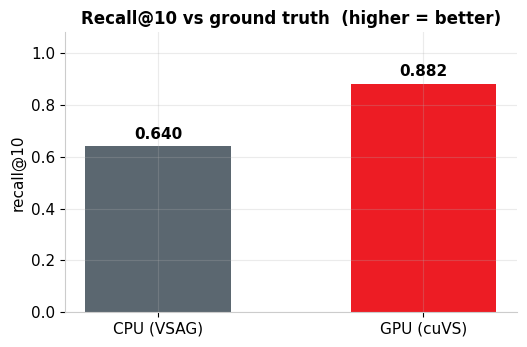

Recall values above are measured for this configuration; single/batch agreement is checked below.


In [9]:
if "sk" not in globals():
    raise RuntimeError("Run the initialization/import cell first, or use Restart Kernel and Run All Cells.")
sk.require_notebook_state(globals(), ['_DATA_READY'], 'Run section 3 data preparation first.')
globals().pop('r_cpu', None)
globals().pop('r_gpu', None)
globals().pop('score', None)
sk.cpu_lateral(100); sk.gpu_batch(100)                    # fill cpu_out / bk_out
r_cpu = sk.recall_at_k("cpu_out"); r_gpu = sk.recall_at_k("bk_out")
print("recall@10   CPU (VSAG): %.4f    GPU (cuVS batch): %.4f" % (r_cpu, r_gpu))

fig, ax = plt.subplots(figsize=(5.4, 3.6))
bars = ax.bar(["CPU (VSAG)", "GPU (cuVS)"], [r_cpu, r_gpu], color=[CPU_GRAY, AMD_RED], width=0.55)
ax.bar_label(bars, fmt="%.3f", padding=3, fontweight="bold")
ax.set_ylabel("recall@10"); ax.set_title("Recall@10 vs ground truth  (higher = better)")
ax.set_ylim(0, 1.08)
plt.tight_layout(); plt.show()
print("Recall values above are measured for this configuration; single/batch agreement is checked below.")

## 7. 总结记分牌


In [10]:
if "sk" not in globals():
    raise RuntimeError("Run the initialization/import cell first, or use Restart Kernel and Run All Cells.")
sk.require_notebook_state(globals(), ['df', 'cpu', 'gpu', 'r_cpu', 'r_gpu'], 'Complete sections 3, 4, 5 and 6 before generating the scoreboard.')
peak = df.speedup.max(); peakN = int(df.N.iloc[df.speedup.idxmax()])
gpu_qps = int(df.gpu_probes_s.max()); cpu_qps = int(df.cpu_probes_s.max())
score = pd.DataFrame([
    {"指标 metric": "单查 single-query",       "结果 result": "GPU %.2f ms  vs  CPU %.2f ms   (no win)" % (gpu, cpu)},
    {"指标 metric": "批量峰值加速 batch peak",  "结果 result": "%.1fx  @ N=%d" % (peak, peakN)},
    {"指标 metric": "GPU 批量吞吐 throughput",  "结果 result": "%d probes/s   (CPU %d/s)" % (gpu_qps, cpu_qps)},
    {"指标 metric": "召回 recall@10",           "结果 result": "cuVS %.3f   vs   VSAG %.3f" % (r_gpu, r_cpu)},
    {"指标 metric": "驱动 how",                 "结果 result": "lib=cuvs + dbms_vector.batch_knn  (no env var)"},
])
score

,指标 metric,结果 result
0,单查 single-query,GPU 13.22 ms vs CPU 7.75 ms (no win)
1,批量峰值加速 batch peak,9.3x @ N=4000
2,GPU 批量吞吐 throughput,3162 probes/s (CPU 340/s)
3,召回 recall@10,cuVS 0.882 vs VSAG 0.640
4,驱动 how,lib=cuvs + dbms_vector.batch_knn (no env var)


### 结论与定位

结果由本次测量生成。重点观察批量增大时的吞吐变化、单条 GPU 固定开销和当前参数的召回。不要把批量查询加速写作 HNSW 索引构建加速，也不要将原课程截图中的 12.7× 固定为本次成绩。

GPU 价值探索：相似度 JOIN、批量向量打分和离线召回评测。源代码和改动说明见本目录 README。


In [11]:
if "sk" not in globals():
    raise RuntimeError("Run the initialization/import cell first, or use Restart Kernel and Run All Cells.")
sk.require_notebook_state(globals(), ['df', 'cpu', 'gpu', 'r_cpu', 'r_gpu'], 'Complete the preceding measurement cells first.')
# Additional checks: fail on incomplete data or missing query results.
import math
for table, expected in [("t_cuvs",10000),("t_vsag",10000)]+[("probes_%d" % v,v) for v in PROBE_SIZES]:
    actual=int(sk.sql_rows("use vec; select count(*) from "+table)[0][0])
    assert actual==expected,(table,actual,expected)
for table in ("cpu_out","bk_out"):
    count=int(sk.sql_rows("use vec; select count(*) from "+table)[0][0])
    assert count==1000,(table,count)
    groups=sk.sql_rows("use vec; select probe_id,count(*),count(distinct neighbor_id) from "+table+" group by probe_id")
    assert len(groups)==100 and all(int(v[1])==10 and int(v[2])==10 for v in groups)
assert list(df.N)==list(PROBE_SIZES)
assert all(math.isfinite(float(v)) and float(v)>0 for name in ("cpu_ms","gpu_ms","speedup") for v in df[name])
# Measure single/batch agreement instead of assuming it.
batch={}
for pid,nid in sk.sql_rows("use vec; select probe_id,neighbor_id from bk_out"):
    batch.setdefault(int(pid),set()).add(int(nid))
matches=0
single_hits=0
gt=sk._load_gt()
for pid,pv in sk.sql_rows("use vec; select id,pv from probes_100 order by id"):
    got=sk.sql_rows("use vec; select c1 from t_cuvs order by l2_distance(c2,'%s') approximate limit 10" % pv)
    single=set(int(row[0]) for row in got)
    assert len(single)==10 and all(0<=v<N_INDEX for v in single)
    matches += single==batch[int(pid)]
    single_hits += len(single & gt[int(pid)])
report={"completed":True,"rows":N_INDEX,"probe_sizes":list(PROBE_SIZES),
        "single_query_ms":{"cpu":cpu,"gpu":gpu},"batch_runs":df.to_dict(orient="records"),
        "recall_at_10":{"cpu":r_cpu,"gpu":r_gpu},
        "sql_results_validated":True,"gpu_single_batch_identical_queries":matches,"gpu_single_batch_checked_queries":100,"gpu_single_query_recall_at_10":single_hits/1000,"scope":"course preinstalled batch-query demo; not HNSW construction"}
Path("results/summary.json").write_text(json.dumps(report,indent=2),encoding="utf-8")
print(json.dumps(report,indent=2))


{
  "completed": true,
  "rows": 10000,
  "probe_sizes": [
    100,
    500,
    1000,
    2000,
    4000
  ],
  "single_query_ms": {
    "cpu": 7.754926104098558,
    "gpu": 13.220578897744417
  },
  "batch_runs": [
    {
      "N": 100,
      "cpu_ms": 318.7,
      "gpu_ms": 1170.2,
      "speedup": 0.27,
      "cpu_probes_s": 314,
      "gpu_probes_s": 85
    },
    {
      "N": 500,
      "cpu_ms": 1488.9,
      "gpu_ms": 975.0,
      "speedup": 1.53,
      "cpu_probes_s": 336,
      "gpu_probes_s": 513
    },
    {
      "N": 1000,
      "cpu_ms": 2947.6,
      "gpu_ms": 983.3,
      "speedup": 3.0,
      "cpu_probes_s": 339,
      "gpu_probes_s": 1017
    },
    {
      "N": 2000,
      "cpu_ms": 5882.8,
      "gpu_ms": 1120.2,
      "speedup": 5.25,
      "cpu_probes_s": 340,
      "gpu_probes_s": 1785
    },
    {
      "N": 4000,
      "cpu_ms": 11802.0,
      "gpu_ms": 1265.0,
      "speedup": 9.33,
      "cpu_probes_s": 339,
      "gpu_probes_s": 3162
    }
  ],
  "recall_at